# 07 — Vendas e lucro: correlação, regressão linear e R²

Percurso: dados → tabela de somatórios → contas do MMQ → verificação Python → resíduos → interpretação.


### Exercício.

Dados os valores de vendas avaliar a correlação com os lucros.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

def mostrar_totais(tabela, colunas):
    """Mostra Σ no rodapé sem acrescentar linhas ao DataFrame de cálculo."""
    rodape = {col: (tabela[col].sum() if col in colunas else '') for col in tabela.columns}
    rodape[tabela.columns[0]] = 'Σ'
    display(pd.concat([tabela, pd.DataFrame([rodape])], ignore_index=True))


### Dados e tabela de cálculo

Se $x$ é Vendas e $y$ é Lucro, precisamos de $\sum x$, $\sum y$, $\sum x^2$, $\sum xy$ para a reta. Para $R^2$, também de $\sum(y_i-\hat y_i)^2$ e $\sum(y_i-\bar y)^2$. A linha Σ aparece só na apresentação.


In [2]:
df=pd.DataFrame({'Vendas':[201,225,305,380,560,600,685,735], 'Lucro':[17,20,21,23,25,24,27,27]})
df['X²']=df.Vendas**2; df['X·Y']=df.Vendas*df.Lucro
mostrar_totais(df,['Vendas','Lucro','X²','X·Y'])


,Vendas,Lucro,X²,X·Y
0,201,17,40401,3417
1,225,20,50625,4500
2,305,21,93025,6405
3,380,23,144400,8740
4,560,25,313600,14000
5,600,24,360000,14400
6,685,27,469225,18495
7,735,27,540225,19845
8,Σ,184,2011501,89802


### Método dos Mínimos Quadrados (MMQ).

A equação da reta da regressão é dada por:

$$
\hat{y} = \alpha + \beta x
$$

onde $\beta$

$$
\beta =
\frac{
\sum_{i=1}^{n} x_i y_i - n\bar{x}\bar{y}
}{
\sum_{i=1}^{n} x_i^2 - n\bar{x}^{\,2}
}
$$


In [3]:
n=len(df); xbar=df.Vendas.mean(); ybar=df.Lucro.mean()
Sxy=df['X·Y'].sum()-n*xbar*ybar
Sxx=df['X²'].sum()-n*xbar**2
beta=Sxy/Sxx; alpha=ybar-beta*xbar
print(f'n={n}; Σx={df.Vendas.sum()}; Σy={df.Lucro.sum()}')
print(f'Σxy={df["X·Y"].sum()}; Σx²={df["X²"].sum()}')
print(f'x̄={xbar:.3f}; ȳ={ybar:.3f}; Sxy={Sxy:.3f}; Sxx={Sxx:.3f}')
print(f'β={beta:.8f}; α={alpha:.8f}; ŷ={alpha:.5f}+{beta:.8f}x')


n=8; Σx=3691; Σy=184
Σxy=89802; Σx²=2011501
x̄=461.375; ȳ=23.000; Sxy=4909.000; Sxx=308565.875
β=0.01590908; α=15.65994700; ŷ=15.65995+0.01590908x


### Verificação independente com `np.polyfit`

O cálculo explícito acima mostra de onde saem os coeficientes. `np.polyfit` confirma os mesmos valores, sem substituir a tabela.


In [4]:
beta_np,alpha_np=np.polyfit(df.Vendas,df.Lucro,1)
print(f'np.polyfit: β={beta_np:.8f}; α={alpha_np:.8f}')
assert np.allclose([beta,alpha],[beta_np,alpha_np])


np.polyfit: β=0.01590908; α=15.65994700


#### Coeficiente de Determinação.

$$
R^2
=
1-
\frac{
\displaystyle\sum_{i=1}^{n}(y_i-\widehat{y}_i)^2
}{
\displaystyle\sum_{i=1}^{n}(y_i-\bar{y})^2
}
$$


In [5]:
df['Lucro estimado']=alpha+beta*df.Vendas
df['Resíduo']=df.Lucro-df['Lucro estimado']
df['Resíduo²']=df.Resíduo**2
df['(Lucro−média)²']=(df.Lucro-ybar)**2
mostrar_totais(df,['Vendas','Lucro','X²','X·Y','Resíduo','Resíduo²','(Lucro−média)²'])
SQres=df['Resíduo²'].sum(); SQtot=df['(Lucro−média)²'].sum()
R2=1-SQres/SQtot
r=df.Vendas.corr(df.Lucro)
print(f'SQres={SQres:.5f}; SQtot={SQtot:.5f}; R²={R2:.5f} ({R2:.2%})')
print(f'r={r:.5f}; r²={r*r:.5f}')


,Vendas,Lucro,X²,X·Y,Lucro estimado,Resíduo,Resíduo²,(Lucro−média)²
0,201,17,40401,3417,18.857673,-1.857673e+00,3.450948,36.0
1,225,20,50625,4500,19.239491,7.605094e-01,0.578375,9.0
2,305,21,93025,6405,20.512217,4.877828e-01,0.237932,4.0
3,380,23,144400,8740,21.705398,1.294602e+00,1.675993,0.0
4,560,25,313600,14000,24.569033,4.309667e-01,0.185732,4.0
5,600,24,360000,14400,25.205397,-1.205397e+00,1.452981,1.0
6,685,27,469225,18495,26.557669,4.423314e-01,0.195657,16.0
7,735,27,540225,19845,27.353123,-3.531227e-01,0.124696,16.0
8,Σ,184,2011501,89802,,3.552714e-15,7.902313,86.0


SQres=7.90231; SQtot=86.00000; R²=0.90811 (90.81%)
r=0.95295; r²=0.90811


### Gráficos e interpretação

A reta é calculada em um vetor de valores de vendas; os resíduos usam referência horizontal em zero.


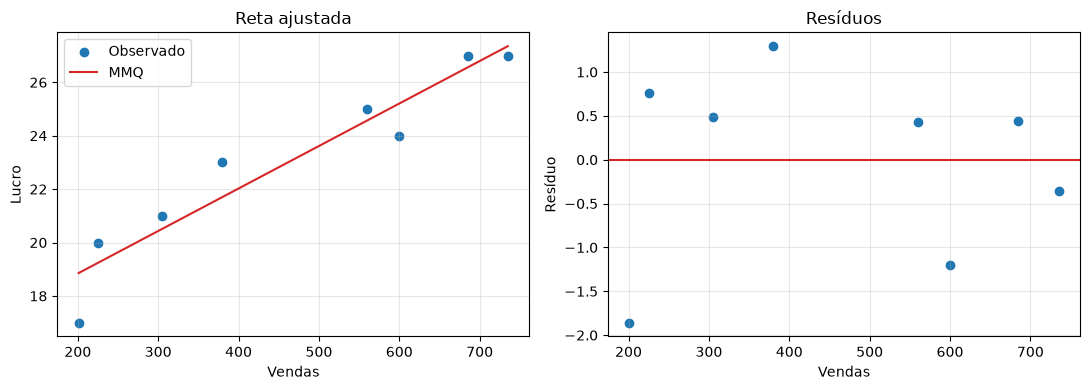

In [6]:
xlinha=np.linspace(df.Vendas.min(),df.Vendas.max(),100)
fig,axes=plt.subplots(1,2,figsize=(11,4))
axes[0].scatter(df.Vendas,df.Lucro,label='Observado')
axes[0].plot(xlinha,alpha+beta*xlinha,color='tab:red',label='MMQ')
axes[0].set(xlabel='Vendas',ylabel='Lucro',title='Reta ajustada'); axes[0].legend()
axes[1].scatter(df.Vendas,df.Resíduo); axes[1].axhline(0,color='tab:red')
axes[1].set(xlabel='Vendas',ylabel='Resíduo',title='Resíduos')
for ax in axes: ax.grid(True,alpha=.3)
plt.tight_layout(); plt.show()


**Interpretação:** $R^2$ informa a proporção da variação do lucro em torno de sua média explicada pela reta ajustada nestes oito pares. No modelo linear com intercepto, $R^2=r^2$. Avalie também o padrão dos resíduos.
